# 05 · Temporal Analytics — JogjaPulse
**Anggota 5: Shafa Aura Yogadiasa - 22/496508/TK/54406**

Data: `data/raw/zenodo/presence_kapanewon_hourly.csv` (Zenodo 10.5281/zenodo.23157460, CC BY 4.0)
Kolom: `kab_code, kab_kota, kapanewon_code, kapanewon, date, hour, n_maids, n_pings` · jam sudah **WIB**.

**Pertanyaan**
1. Bagaimana pola aktivitas per jam dalam sehari?
2. Apa beda weekday vs weekend?
3. Bagaimana efek periode khusus: libur Natal–Tahun Baru, Ramadan, menjelang Lebaran?
4. (Prediktif, opsional) Seberapa akurat aktivitas per jam bisa diprediksi?

**Tiga hal penting dari README dataset**
- `n_maids` = jumlah device **unik** → **tidak boleh dijumlah** antar kapanewon/jam/hari. Kita pakai **rata-rata per kapanewon**.
- Baris dengan `n_maids < 5` disensor (k = 5) → baris yang tidak ada ≠ nol.
- Jumlah device **anjlok ±4× mulai 16 Feb 2022** (lihat bagian 2). Itu perubahan pasokan data, bukan orang berhenti bepergian. Jadi analisis memakai **indeks yang dinormalisasi per periode data**.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path

DATA = Path("../data/raw/zenodo/presence_kapanewon_hourly.csv")
OUT  = Path("../outputs/temporal"); OUT.mkdir(parents=True, exist_ok=True)

# Warna (palet konsisten untuk semua grafik)
C1, C2, GREY, INK = "#2a78d6", "#eb6834", "#9a9893", "#52514e"
SEQ = LinearSegmentedColormap.from_list("seq", ["#f0f6fe", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": .6,
                     "axes.edgecolor": GREY, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
                     "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "lines.linewidth": 2})
HARI = ["Sen", "Sel", "Rab", "Kam", "Jum", "Sab", "Min"]

df = pd.read_csv(DATA, dtype={"kab_code": str, "kapanewon_code": str}, parse_dates=["date"])
df["dow"] = df["date"].dt.dayofweek          # 0 = Senin
df["weekend"] = df["dow"] >= 5
print(df.shape); df.head()

Matplotlib is building the font cache; this may take a moment.


(230418, 10)


/var/folders/75/cxpcwf4n5xx45dndfq9dqz6m0000gn/T/ipykernel_12320/1061319205.py:20: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["dow"] = df["date"].dt.dayofweek          # 0 = Senin


,kab_code,kab_kota,kapanewon_code,kapanewon,date,hour,n_maids,n_pings,dow,weekend
0,34.01,KULON PROGO,34.01.01,TEMON,2021-12-01,0,16,66,2,False
1,34.01,KULON PROGO,34.01.02,WATES,2021-12-01,0,58,101,2,False
2,34.01,KULON PROGO,34.01.03,PANJATAN,2021-12-01,0,11,32,2,False
3,34.01,KULON PROGO,34.01.04,GALUR,2021-12-01,0,9,50,2,False
4,34.01,KULON PROGO,34.01.05,LENDAH,2021-12-01,0,14,74,2,False


## 1. Cek kualitas singkat

In [2]:
print("Rentang tanggal :", df.date.min().date(), "→", df.date.max().date(), f"({df.date.nunique()} hari)")
print("Kapanewon        :", df.kapanewon_code.nunique())
print("Jam              :", sorted(df.hour.unique())[:3], "...", sorted(df.hour.unique())[-1])
print("Duplikat key     :", df.duplicated(["kapanewon_code", "date", "hour"]).sum())
print("Missing          :", df.isna().sum().sum())
n_possible = df.kapanewon_code.nunique() * df.date.nunique() * 24
print(f"Baris terpublikasi: {len(df):,} dari {n_possible:,} kemungkinan ({len(df)/n_possible:.1%}); sisanya disensor (k=5)")

Rentang tanggal : 2021-12-01 → 2022-04-30 (151 hari)
Kapanewon        : 78
Jam              : [np.int64(0), np.int64(1), np.int64(2)] ... 23
Duplikat key     : 0
Missing          : 0
Baris terpublikasi: 230,418 dari 282,672 kemungkinan (81.5%); sisanya disensor (k=5)


## 2. Temuan kualitas data: jumlah device anjlok pertengahan Februari

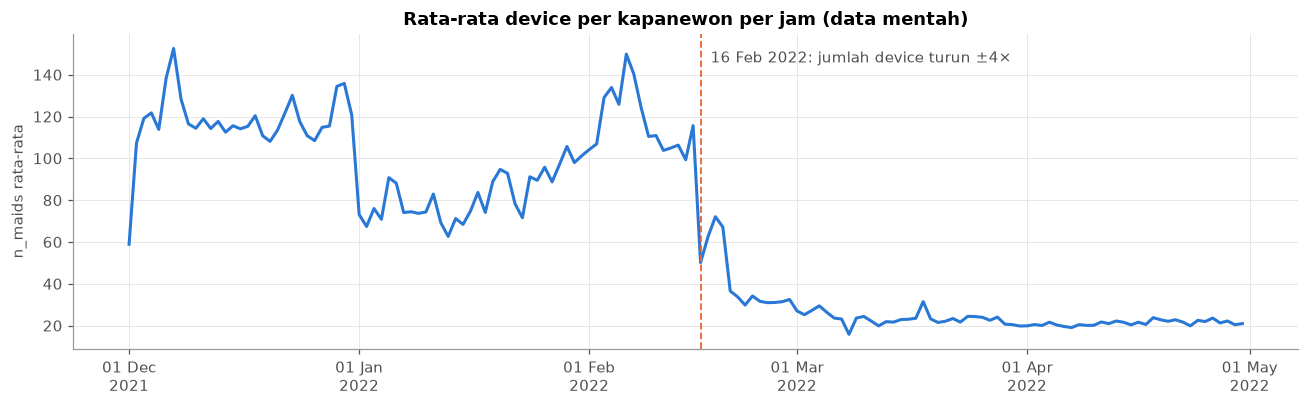

Sebelum 16 Feb: 103.3 | Sesudah 20 Feb: 23.6


In [3]:
daily = df.groupby("date").agg(mean_maids=("n_maids", "mean"), rows=("n_maids", "size"))
BREAK = pd.Timestamp("2022-02-16")

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(daily.index, daily.mean_maids, color=C1)
ax.axvline(BREAK, color=C2, ls="--", lw=1.2)
ax.text(BREAK, ax.get_ylim()[1]*.95, "  16 Feb 2022: jumlah device turun ±4×", color=INK, va="top")
ax.set(title="Rata-rata device per kapanewon per jam (data mentah)", ylabel="n_maids rata-rata")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%Y"))
plt.tight_layout(); plt.savefig(OUT/"00_cek_perubahan_pasokan_data.png", dpi=150); plt.show()

print("Sebelum 16 Feb:", round(daily.loc[:"2022-02-15", "mean_maids"].mean(), 1),
      "| Sesudah 20 Feb:", round(daily.loc["2022-02-20":, "mean_maids"].mean(), 1))

**Bagaimana menanganinya.** Selain anjlok 16 Feb, level device juga naik-turun pelan sepanjang periode (bisa karena pasokan data, bisa karena mobilitas sungguhan, dan dari data ini keduanya tidak bisa dipisahkan).
Jadi kita **tidak menafsirkan level absolut jangka panjang**. Yang dianalisis adalah aktivitas **relatif terhadap kondisi normal di sekitarnya**:

`idx = n_maids ÷ baseline lokal × 100`, dengan *baseline lokal* = median rata-rata harian kapanewon itu dalam jendela ±14 hari (dihitung terpisah sebelum dan sesudah 16 Feb; 16–19 Feb dibuang).

- idx 100 = tingkat normal kapanewon itu pada minggu-minggu tersebut
- Pola jam, hari, dan libur pendek tetap terlihat; tren pasokan data hilang.
- Hanya kapanewon yang ≥ 80% jamnya terpublikasi yang dipakai, supaya sensor k=5 tidak mendistorsi.

In [4]:
df["regime"] = np.select([df.date < BREAK, df.date >= "2022-02-20"], ["A", "B"], default="transisi")
d = df[df.regime != "transisi"].copy()

days = d.groupby("regime").date.nunique()
cov = d.groupby(["kapanewon_code", "regime"]).size().unstack() / (days * 24)
keep = cov[(cov >= .8).all(axis=1)].index
print(f"Kapanewon dipakai: {len(keep)} dari {d.kapanewon_code.nunique()} (sisanya terlalu banyak jam tersensor)")
d = d[d.kapanewon_code.isin(keep)]

# baseline lokal per kapanewon
dm = d.groupby(["kapanewon_code", "regime", "date"]).n_maids.mean().rename("day_mean").reset_index()
dm["base"] = (dm.groupby(["kapanewon_code", "regime"]).day_mean
                .transform(lambda x: x.rolling(29, center=True, min_periods=10).median()))
d = d.merge(dm[["kapanewon_code", "date", "base"]], on=["kapanewon_code", "date"])
d["idx"] = d.n_maids / d.base * 100

# Seri DIY per jam = rata-rata indeks antar kapanewon
hourly = d.groupby(["date", "hour"], as_index=False).agg(idx=("idx", "mean"), regime=("regime", "first"))
hourly["ts"] = hourly.date + pd.to_timedelta(hourly.hour, unit="h")
hourly["dow"] = hourly.date.dt.dayofweek; hourly["weekend"] = hourly.dow >= 5

Kapanewon dipakai: 32 dari 78 (sisanya terlalu banyak jam tersensor)


/var/folders/75/cxpcwf4n5xx45dndfq9dqz6m0000gn/T/ipykernel_12320/65164176.py:20: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  hourly["dow"] = hourly.date.dt.dayofweek; hourly["weekend"] = hourly.dow >= 5


## 3. Profil per jam: weekday vs weekend

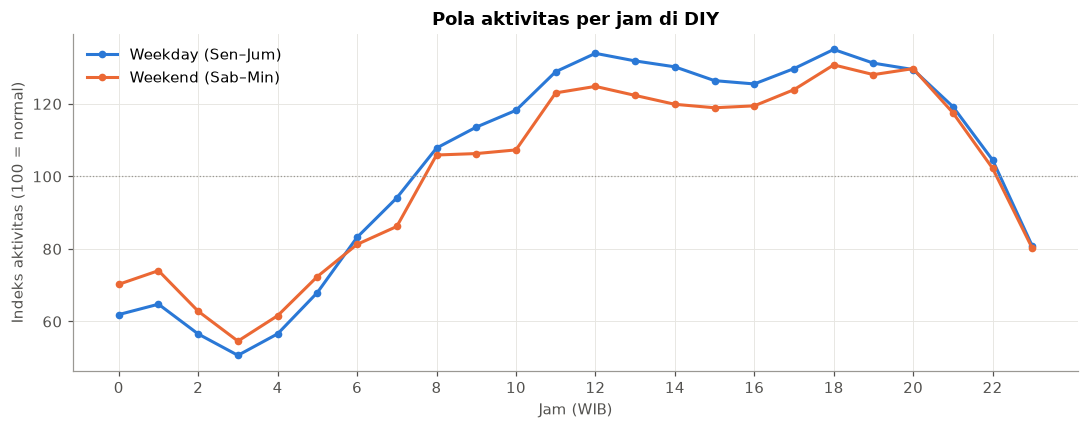

Jam puncak weekday: 18 | weekend: 18
Jam tersepi weekday: 3 | weekend: 3
Level harian weekend vs weekday: -2.4%


,Weekday,Weekend,selisih_pct
hour,,,
0,61.9,70.3,13.5
1,64.8,74.0,14.3
2,56.6,62.8,11.1
3,50.7,54.6,7.7
4,56.6,61.6,8.8
5,68.0,72.4,6.5
6,83.2,81.3,-2.3
7,94.1,86.2,-8.4
8,107.8,105.9,-1.8


In [5]:
prof = hourly.groupby(["weekend", "hour"]).idx.mean().unstack(0)
prof.columns = ["Weekday", "Weekend"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(prof.index, prof.Weekday, color=C1, marker="o", ms=4, label="Weekday (Sen–Jum)")
ax.plot(prof.index, prof.Weekend, color=C2, marker="o", ms=4, label="Weekend (Sab–Min)")
ax.axhline(100, color=GREY, lw=.8, ls=":")
ax.set(title="Pola aktivitas per jam di DIY", xlabel="Jam (WIB)", ylabel="Indeks aktivitas (100 = normal)")
ax.set_xticks(range(0, 24, 2)); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(OUT/"01_profil_jam_weekday_weekend.png", dpi=150); plt.show()

tab = prof.assign(selisih_pct=(prof.Weekend / prof.Weekday - 1) * 100).round(1)
print("Jam puncak weekday:", prof.Weekday.idxmax(), "| weekend:", prof.Weekend.idxmax())
print("Jam tersepi weekday:", prof.Weekday.idxmin(), "| weekend:", prof.Weekend.idxmin())
lvl = hourly.groupby(["date", "weekend"]).idx.mean().groupby("weekend").mean()
print(f"Level harian weekend vs weekday: {(lvl[True]/lvl[False]-1)*100:+.1f}%")
tab

## 4. Heatmap hari × jam

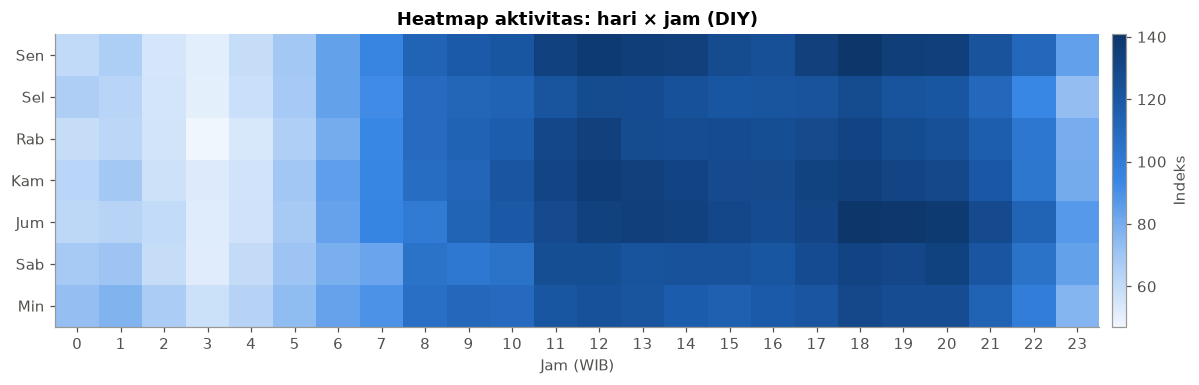

In [6]:
hm = hourly.groupby(["dow", "hour"]).idx.mean().unstack("hour"); hm.index = HARI
fig, ax = plt.subplots(figsize=(12, 3.6))
im = ax.imshow(hm.values, aspect="auto", cmap=SEQ)
ax.set_xticks(range(24)); ax.set_xticklabels(range(24)); ax.set_yticks(range(7)); ax.set_yticklabels(HARI)
ax.grid(False); ax.set(title="Heatmap aktivitas: hari × jam (DIY)", xlabel="Jam (WIB)")
fig.colorbar(im, ax=ax, label="Indeks", pad=.01)
plt.tight_layout(); plt.savefig(OUT/"02_heatmap_hari_jam.png", dpi=150); plt.show()

## 5. Tren harian & periode khusus
Tanggal libur di `EVENTS` **dicek ulang** ke SKB 3 Menteri 2021/2022 sebelum masuk slide.

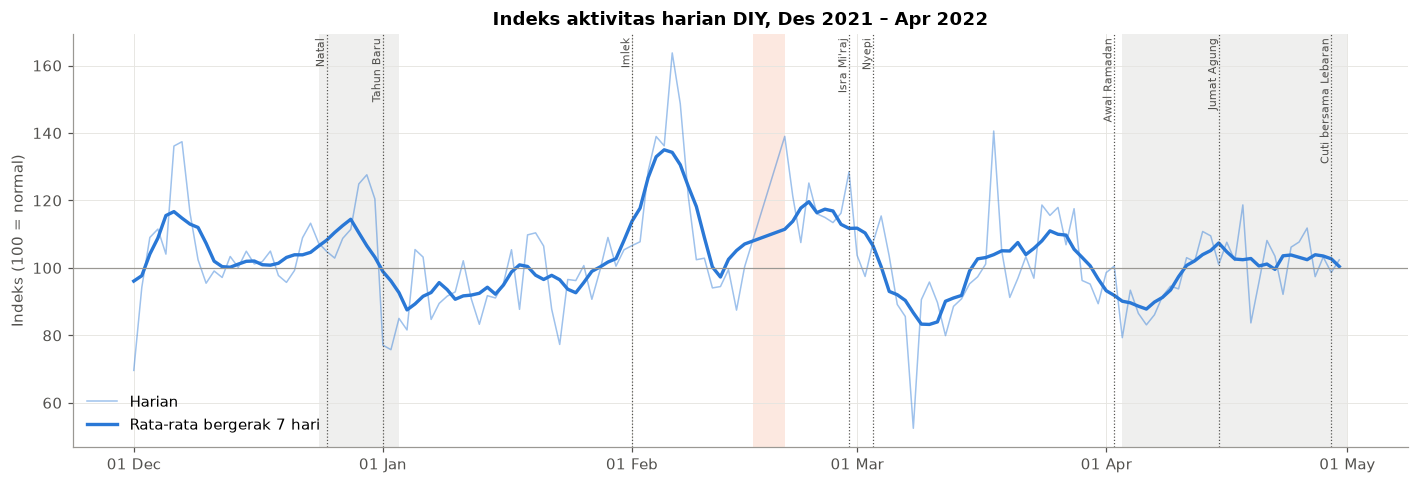

In [7]:
EVENTS = {
    "Natal": "2021-12-25", "Tahun Baru": "2022-01-01", "Imlek": "2022-02-01",
    "Isra Mi'raj": "2022-02-28", "Nyepi": "2022-03-03", "Awal Ramadan": "2022-04-02",
    "Jumat Agung": "2022-04-15", "Cuti bersama Lebaran": "2022-04-29",
}
PERIODS = {   # periode pendek; Ramadan (26 hari) tidak dibandingkan levelnya karena sepanjang jendela baseline
    "Libur Nataru (24 Des–2 Jan)": ("2021-12-24", "2022-01-02"),
    "Ramadan (3–28 Apr)":          ("2022-04-03", "2022-04-28"),
    "Jelang Lebaran (29–30 Apr)":  ("2022-04-29", "2022-04-30"),
}
SHORT = ["Libur Nataru (24 Des–2 Jan)", "Jelang Lebaran (29–30 Apr)"]

day_idx = hourly.groupby("date").idx.mean().to_frame("idx")
day_idx["ma7"] = day_idx.idx.rolling(7, center=True, min_periods=4).mean()

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(day_idx.index, day_idx.idx, color=C1, lw=1, alpha=.45, label="Harian")
ax.plot(day_idx.index, day_idx.ma7, color=C1, lw=2.2, label="Rata-rata bergerak 7 hari")
for a, b in PERIODS.values():
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b) + pd.Timedelta(days=1), color=GREY, alpha=.15, lw=0)
ax.axvspan(BREAK, pd.Timestamp("2022-02-20"), color=C2, alpha=.15, lw=0)
ymax = ax.get_ylim()[1]
for name, t in EVENTS.items():
    ax.axvline(pd.Timestamp(t), color=INK, ls=":", lw=.8)
    ax.text(pd.Timestamp(t), ymax, name + " ", rotation=90, va="top", ha="right", fontsize=7.5, color=INK)
ax.axhline(100, color=GREY, lw=.8)
ax.set(title="Indeks aktivitas harian DIY, Des 2021 – Apr 2022", ylabel="Indeks (100 = normal)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); ax.legend(frameon=False, loc="lower left")
plt.tight_layout(); plt.savefig(OUT/"03_tren_harian.png", dpi=150); plt.show()

In [8]:
# Hari libur & periode pendek vs hari biasa di sekitarnya (idx 100 = normal lokal)
special = pd.Series(False, index=day_idx.index)
for a, b in PERIODS.values(): special |= (day_idx.index >= a) & (day_idx.index <= b)
for t in EVENTS.values(): special |= day_idx.index == t
normal = day_idx.idx[~special]
dow_norm = normal.groupby(normal.index.dayofweek).mean()   # pembanding: hari biasa dengan hari yang sama

rows = []
for name, t in EVENTS.items():
    t = pd.Timestamp(t)
    if t in day_idx.index:
        rows.append({"tanggal": t.date(), "event": name, "hari": HARI[t.dayofweek],
                     "indeks": day_idx.idx[t], "hari_biasa_sama": dow_norm[t.dayofweek]})
for name in SHORT:
    a, b = PERIODS[name]
    rows.append({"tanggal": f"{a} s.d. {b}", "event": name, "hari": "-",
                 "indeks": day_idx.loc[a:b, "idx"].mean(), "hari_biasa_sama": normal.mean()})
ev = pd.DataFrame(rows); ev["selisih_pct"] = (ev.indeks / ev.hari_biasa_sama - 1) * 100
ev.round(1)

/var/folders/75/cxpcwf4n5xx45dndfq9dqz6m0000gn/T/ipykernel_12320/3828408496.py:6: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dow_norm = normal.groupby(normal.index.dayofweek).mean()   # pembanding: hari biasa dengan hari yang sama
/var/folders/75/cxpcwf4n5xx45dndfq9dqz6m0000gn/T/ipykernel_12320/3828408496.py:12: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  rows.append({"tanggal": t.date(), "event": name, "hari": HARI[t.dayofweek],
/var/folders/75/cxpcwf4n5xx45dndfq9dqz6m0000gn/T/ipykernel_12320/3828408496.py:13: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "indeks": day_idx.idx[t], "hari_biasa_sama": dow_norm[t.dayofweek]})


,tanggal,event,hari,indeks,hari_biasa_sama,selisih_pct
0,2021-12-25,Natal,Sab,104.9,103.1,1.8
1,2022-01-01,Tahun Baru,Sab,77.1,103.1,-25.2
2,2022-02-01,Imlek,Sel,106.6,99.0,7.7
3,2022-02-28,Isra Mi'raj,Sen,128.5,104.6,22.9
4,2022-03-03,Nyepi,Kam,107.6,103.4,4.1
5,2022-04-02,Awal Ramadan,Sab,100.5,103.1,-2.5
6,2022-04-15,Jumat Agung,Jum,101.0,106.4,-5.1
7,2022-04-29,Cuti bersama Lebaran,Jum,98.6,106.4,-7.3
8,2021-12-24 s.d. 2022-01-02,Libur Nataru (24 Des–2 Jan),-,106.1,103.1,3.0
9,2022-04-29 s.d. 2022-04-30,Jelang Lebaran (29–30 Apr),-,100.5,103.1,-2.5


## 6. Ramadan: apakah jam ramai bergeser?

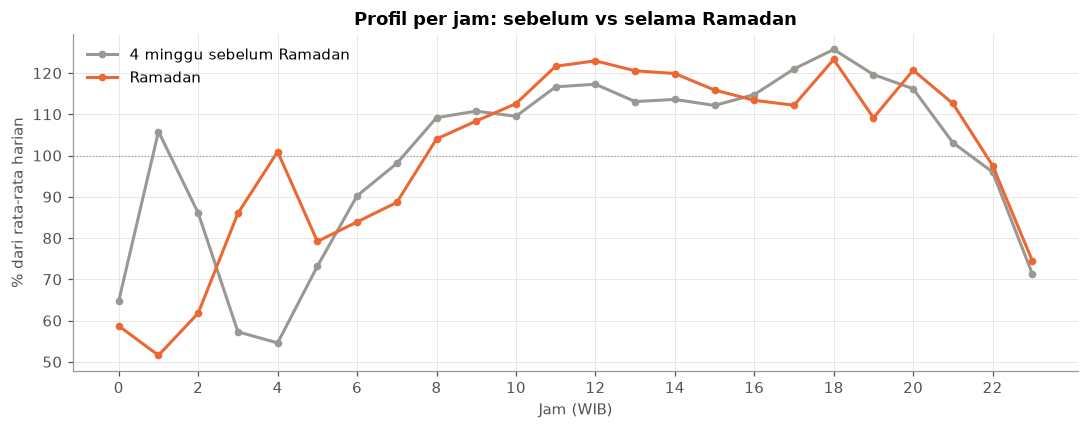

,sebelum,ramadan,selisih_pct
hour,,,
1,105.8,51.6,-51.3
2,86.1,61.8,-28.2
7,98.1,88.6,-9.6
0,64.8,58.7,-9.4
19,119.6,109.1,-8.8
17,121.0,112.2,-7.3
6,90.2,83.9,-7.0
8,109.2,104.0,-4.7
9,110.8,108.4,-2.2


In [9]:
# Bandingkan BENTUK pola: tiap jam dibagi rata-rata hari itu (100 = rata-rata harian)
h2 = hourly.copy(); h2["shape"] = h2.idx / h2.groupby("date").idx.transform("mean") * 100
pre = h2[(h2.date >= "2022-03-05") & (h2.date <= "2022-04-01")].groupby("hour")["shape"].mean()
ram = h2[(h2.date >= "2022-04-03") & (h2.date <= "2022-04-28")].groupby("hour")["shape"].mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(pre.index, pre, color=GREY, marker="o", ms=4, label="4 minggu sebelum Ramadan")
ax.plot(ram.index, ram, color=C2, marker="o", ms=4, label="Ramadan")
ax.set(title="Profil per jam: sebelum vs selama Ramadan", xlabel="Jam (WIB)", ylabel="% dari rata-rata harian")
ax.axhline(100, color=GREY, lw=.8, ls=":")
ax.set_xticks(range(0, 24, 2)); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(OUT/"04_ramadan_vs_sebelum.png", dpi=150); plt.show()

(pd.DataFrame({"sebelum": pre, "ramadan": ram}).assign(selisih_pct=lambda x: (x.ramadan / x.sebelum - 1) * 100)
   .round(1).sort_values("selisih_pct"))

## 7. Bentuk pola harian per kapanewon (jembatan ke analisis spasial)

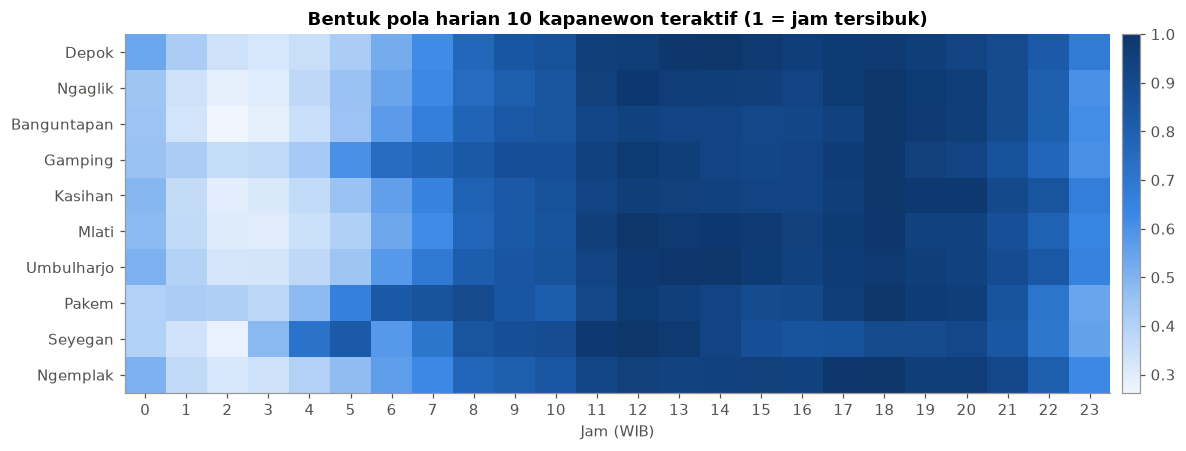

,jam_puncak
kapanewon,
DEPOK,14
NGAGLIK,18
BANGUNTAPAN,18
GAMPING,18
KASIHAN,18
MLATI,12
UMBULHARJO,14
PAKEM,18
SEYEGAN,12


In [10]:
top = df.groupby("kapanewon").n_maids.mean().nlargest(10).index
sub = d[d.kapanewon.isin(top)]
shape = sub.groupby(["kapanewon", "hour"]).idx.mean().unstack()
shape = shape.div(shape.max(axis=1), axis=0).loc[top]   # 1 = jam tersibuk kapanewon itu

fig, ax = plt.subplots(figsize=(12, 4.2))
im = ax.imshow(shape.values, aspect="auto", cmap=SEQ, vmin=shape.values.min(), vmax=1)
ax.set_xticks(range(24)); ax.set_yticks(range(len(shape))); ax.set_yticklabels(shape.index.str.title())
ax.grid(False); ax.set(title="Bentuk pola harian 10 kapanewon teraktif (1 = jam tersibuk)", xlabel="Jam (WIB)")
fig.colorbar(im, ax=ax, pad=.01)
plt.tight_layout(); plt.savefig(OUT/"05_pola_kapanewon_top10.png", dpi=150); plt.show()
shape.idxmax(axis=1).rename("jam_puncak").to_frame()

## 8. (Prediktif) Forecast aktivitas per jam
Target: rata-rata `n_maids` per kapanewon per jam (data mentah, regime B saja supaya skalanya konsisten).
Latih 20 Feb – 10 Apr, uji 11–24 Apr (sebelum cuti Lebaran). Model dibandingkan dengan MAPE:
1. **Naive harian**: nilai jam yang sama kemarin.
2. **Naive mingguan**: nilai jam & hari yang sama minggu lalu.
3. **Rata-rata 3 minggu**: rata-rata jam & hari yang sama selama 3 minggu sebelumnya.

,model,MAPE_%
0,Naive harian,12.1
1,Naive mingguan,15.8
2,Rata-rata 3 minggu,24.2


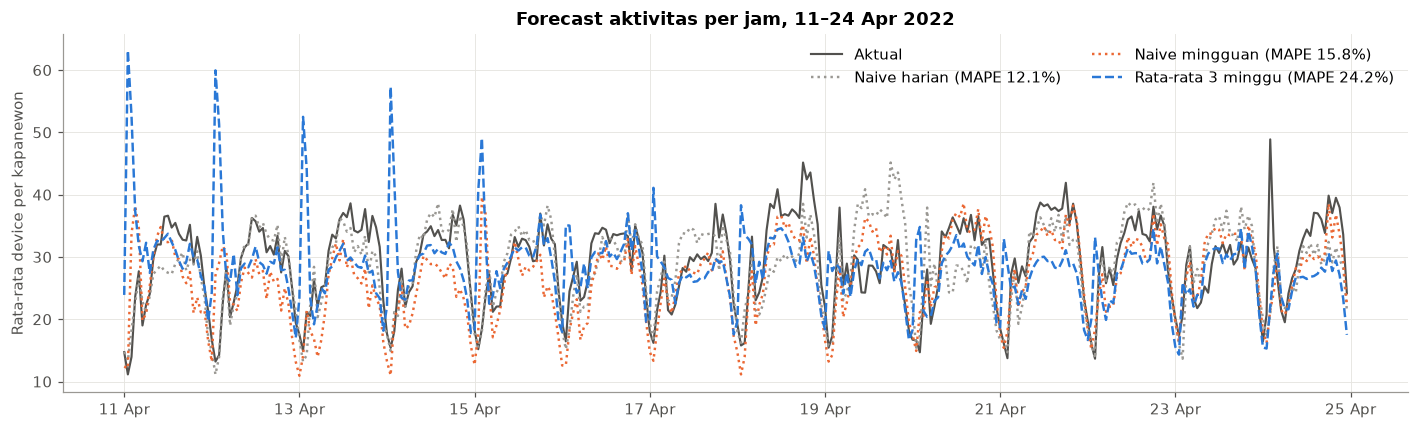

In [11]:
raw = (d[d.regime == "B"].groupby(["date", "hour"]).n_maids.mean().reset_index()
         .assign(ts=lambda x: x.date + pd.to_timedelta(x.hour, unit="h")).set_index("ts").n_maids.asfreq("h"))
raw = raw.interpolate(limit=3)
TR_B, TE_A, TE_B = "2022-04-10 23:00", "2022-04-11", "2022-04-24 23:00"
train, test = raw[:TR_B], raw[TE_A:TE_B]

preds = {
    "Naive harian":   raw.shift(24)[TE_A:TE_B],
    "Naive mingguan": raw.shift(24 * 7)[TE_A:TE_B],
}
preds["Rata-rata 3 minggu"] = pd.concat([raw.shift(24 * 7 * k) for k in (1, 2, 3)], axis=1).mean(axis=1)[TE_A:TE_B]

def mape(y, yh):
    m = y.notna() & yh.notna(); return (abs(y[m] - yh[m]) / y[m]).mean() * 100
res = pd.DataFrame({"model": list(preds), "MAPE_%": [mape(test, p) for p in preds.values()]}).round(1)
display(res)

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(test.index, test, color=INK, lw=1.4, label="Aktual")
for (name, p), col, ls in zip(preds.items(), [GREY, C2, C1], [":", ":", "--"]):
    ax.plot(p.index, p, color=col, ls=ls, lw=1.6, label=f"{name} (MAPE {mape(test, p):.1f}%)")
ax.set(title="Forecast aktivitas per jam, 11–24 Apr 2022", ylabel="Rata-rata device per kapanewon")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); ax.legend(frameon=False, ncol=2)
plt.tight_layout(); plt.savefig(OUT/"06_forecast.png", dpi=150); plt.show()

## 9. Insight

**1. Ritme harian DIY: sepi pukul 03.00, puncak pukul 18.00.**
Aktivitas paling rendah pukul 03.00 (indeks ±51 di hari kerja), naik tajam pukul 06.00–08.00, lalu stabil tinggi dari 11.00 sampai 20.00 dengan puncak pukul 18.00 (indeks 135). Jam puncak ±2,7× jam tersepi. Bentuk pola ini sama di weekday maupun weekend.

**2. Weekend bukan sekadar lebih sepi, tetapi jamnya bergeser.**
Pada jam kerja/kuliah (07.00–16.00) weekend 5–9% lebih sepi daripada weekday, tetapi pada dini hari (00.00–05.00) weekend 7–14% lebih ramai. Pukul 20.00 keduanya sama. Secara total harian, weekend hanya 2,4% lebih rendah. Di heatmap, sore Senin dan Jumat (18.00–20.00) adalah waktu paling ramai dalam seminggu.

**3. Ramadan menggeser jam aktivitas: sahur, berbuka, tarawih.**
Dibandingkan 4 minggu sebelumnya, aktivitas pukul 03.00 naik 50% dan pukul 04.00 naik 85% (sahur). Pukul 19.00 aktivitas turun ±9% (berbuka), lalu naik lagi pukul 20.00–21.00 (+4% s.d. +9%, tarawih).

**4. Di antara hari libur, hanya Tahun Baru yang jelas berbeda.**
Tanggal 1 Januari 2022 ±25% lebih sepi dibanding hari Sabtu biasa. Natal (+2%) dan libur Nataru secara keseluruhan (+3%) tidak berbeda nyata dari hari biasa. Jumat Agung (−5%) dan cuti bersama Lebaran 29 April (−7%) sedikit lebih sepi.

**5. Pusat kegiatan vs permukiman punya jam puncak berbeda.**
Depok (kawasan kampus) dan Umbulharjo (pusat kota) paling ramai pukul 14.00, sedangkan Ngaglik, Banguntapan, Gamping, Kasihan, dan Ngemplak (kawasan permukiman) paling ramai pukul 18.00. Polanya cocok dengan pergerakan siang ke pusat kegiatan lalu sore kembali ke rumah.

**6. (Prediktif) Pola per jam sangat berulang dari hari ke hari.**
Model paling sederhana, "nilai jam yang sama kemarin", memberi error terkecil (MAPE 12,1%), lebih baik daripada naive mingguan (15,8%) dan rata-rata 3 minggu (24,2%).

### Keterbatasan
- **Perubahan pasokan data:** jumlah device turun ±4× sejak 16 Feb 2022 dan level naik-turun pelan sepanjang periode. Karena itu analisis memakai indeks relatif terhadap baseline lokal ±14 hari; level jangka panjang (misalnya apakah Ramadan lebih sepi secara keseluruhan) tidak bisa disimpulkan.
- **Sensor k = 5:** hanya 32 dari 78 kapanewon yang dipakai (≥ 80% jamnya terpublikasi), sehingga hasil didominasi wilayah perkotaan dan sekitarnya.
- **Bias sumber data:** data berasal dari SDK iklan di aplikasi seluler, sehingga 1 device ≠ 1 orang dan pengguna aplikasi tertentu lebih terwakili.
- **Periode terbatas:** hanya 5 bulan (Des 2021 – Apr 2022) di masa pandemi, belum tentu mewakili kondisi normal.
- **Tidak ditafsirkan:** Isra Mi'raj (+23%) terlalu dekat dengan masa transisi data, dan lonjakan pukul 01.00 pada Maret 2022 kemungkinan anomali data.
